# Healthcare Data Analytics: Patient Encounter & Operational Performance Analysis

**Deliverable Type:** Python Exploratory Data Analysis & Business Intelligence  
**Target Audience:** Hospital Executive Leadership, Clinical Operations Directors, Revenue Cycle Managers  
**Dataset:** Synthetic Healthcare Encounter Records (55,500 raw entries)  

---

## 1. Business Problem and Project Objectives

Modern hospital networks operate under stringent requirements to balance clinical quality, bed availability, emergency department readiness, and financial sustainability. Executive leaders require continuous data intelligence to answer critical operational questions:

1. **Patient Demographics & Clinical Profile:** What are the predominant medical conditions and demographic profiles across hospital admissions?
2. **Bed Capacity & Inpatient Length of Stay (LOS):** How long are patients occupying hospital beds, and does length of stay vary by admission urgency?
3. **Financial Consistency & Payer Mix:** How are treatment billing amounts distributed over time? Do patient factors such as age drive total costs? Are revenues dependent on a single insurance provider?
4. **Data Integrity & Financial Auditing:** What anomalies exist in admission and billing records (such as duplicate entries and negative billing amounts), and what are the governance implications?
5. **Operational Capacity Planning:** When did historical emergency surges occur, and what diagnostic patterns characterize high-acuity emergency cases?

### Source of Truth Notice
This analysis evaluates synthetic encounter-level healthcare records. Each row captures an encounter rather than a unique longitudinal patient identity. Analytical metrics, distributions, and statistical tests reported in this study strictly reflect the empirical data.

---

## 2. Dataset Overview

In this section, we initialize the analytical environment with standard data science libraries (`pandas`, `numpy`, `matplotlib`, `seaborn`) and load the encounter records. Robust path resolution is implemented so that the notebook executes seamlessly whether run from the `analysis/` directory or the repository root.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Visual formatting configurations
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 110

# Flexible path resolution to load healthcare_dataset.csv
possible_paths = [
    os.path.join('..', 'data', 'healthcare_dataset.csv'),
    os.path.join('data', 'healthcare_dataset.csv'),
    'healthcare_dataset.csv'
]
dataset_path = next((path for path in possible_paths if os.path.exists(path)), None)

if not dataset_path:
    raise FileNotFoundError("Could not find 'healthcare_dataset.csv'. Please place it in data/ or the working directory.")

df_raw = pd.read_csv(dataset_path)
print(f"Dataset successfully loaded from: {dataset_path}")
print(f"Initial Dimensions: {df_raw.shape[0]:,} rows | {df_raw.shape[1]} columns")

Dataset successfully loaded from: ..\data\healthcare_dataset.csv
Initial Dimensions: 55,500 rows | 15 columns


In [2]:
# Display the first 5 records of the raw dataset
df_raw.head()

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results
0,Bobby JacksOn,30,Male,B-,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.281306,328,Urgent,2024-02-02,Paracetamol,Normal
1,LesLie TErRy,62,Male,A+,Obesity,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.327287,265,Emergency,2019-08-26,Ibuprofen,Inconclusive
2,DaNnY sMitH,76,Female,A-,Obesity,2022-09-22,Tiffany Mitchell,Cook PLC,Aetna,27955.096079,205,Emergency,2022-10-07,Aspirin,Normal
3,andrEw waTtS,28,Female,O+,Diabetes,2020-11-18,Kevin Wells,"Hernandez Rogers and Vang,",Medicare,37909.782410,450,Elective,2020-12-18,Ibuprofen,Abnormal
4,adrIENNE bEll,43,Female,AB+,Cancer,2022-09-19,Kathleen Hanna,White-White,Aetna,14238.317814,458,Urgent,2022-10-09,Penicillin,Abnormal


In [3]:
# Column specifications and memory footprint
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 55500 entries, 0 to 55499
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Name                55500 non-null  str    
 1   Age                 55500 non-null  int64  
 2   Gender              55500 non-null  str    
 3   Blood Type          55500 non-null  str    
 4   Medical Condition   55500 non-null  str    
 5   Date of Admission   55500 non-null  str    
 6   Doctor              55500 non-null  str    
 7   Hospital            55500 non-null  str    
 8   Insurance Provider  55500 non-null  str    
 9   Billing Amount      55500 non-null  float64
 10  Room Number         55500 non-null  int64  
 11  Admission Type      55500 non-null  str    
 12  Discharge Date      55500 non-null  str    
 13  Medication          55500 non-null  str    
 14  Test Results        55500 non-null  str    
dtypes: float64(1), int64(2), str(12)
memory usage: 12.3 MB


---

## 3. Data Quality, Auditing & Cleaning

Data quality auditing is essential before deriving operational conclusions. We assess:
- Completeness (missing/null values)
- Record uniqueness (duplicate detection and deduplication)
- String formatting and consistency
- Financial anomalies (negative billing amounts)
- Temporal parsing and feature engineering (Length of Stay)

In [4]:
# 1. Missing Value Audit
missing_counts = df_raw.isnull().sum()
print("Missing values per column:")
print(missing_counts[missing_counts > 0] if missing_counts.sum() > 0 else "Zero missing values detected across all columns.")

Missing values per column:
Zero missing values detected across all columns.


### Record Deduplication
We inspect the dataset for exact duplicate encounter rows. Any duplicate records are audited and removed to ensure clean metrics.

In [5]:
# Audit duplicate records
duplicate_rows = df_raw.duplicated().sum()
print(f"Total duplicate records identified: {duplicate_rows:,}")

# Deduplicate dataset and create an explicit copy to prevent SettingWithCopy warnings
df = df_raw.drop_duplicates().copy()
print(f"Post-cleaning encounter count: {df.shape[0]:,} records (534 duplicates eliminated)")

Total duplicate records identified: 534


Post-cleaning encounter count: 54,966 records (534 duplicates eliminated)


### Patient Name Normalization
Raw patient names exhibit irregular casing (e.g., `Bobby JacksOn`, `LesLie TErRy`). We standardize all names to title case and trim whitespace.

In [6]:
# Standardize patient names
df['Name'] = df['Name'].str.strip().str.title()
df[['Name', 'Doctor', 'Hospital']].head()

,Name,Doctor,Hospital
0,Bobby Jackson,Matthew Smith,Sons and Miller
1,Leslie Terry,Samantha Davies,Kim Inc
2,Danny Smith,Tiffany Mitchell,Cook PLC
3,Andrew Watts,Kevin Wells,"Hernandez Rogers and Vang,"
4,Adrienne Bell,Kathleen Hanna,White-White


### Financial Anomaly Audit: Negative Billing Amounts
During data auditing, records with negative values in the `Billing Amount` column were identified. Rather than silently deleting or zeroing them, we isolate and examine their characteristics.

In [7]:
# Isolate negative billing records
negative_bills = df[df['Billing Amount'] < 0].copy()
print(f"Encounters with negative billing amounts: {len(negative_bills)}")
print("Summary statistics of negative billing amounts ($):")
negative_bills['Billing Amount'].describe()

Encounters with negative billing amounts: 106
Summary statistics of negative billing amounts ($):


count     106.000000
mean     -502.472497
std       429.857027
min     -2008.492140
25%      -803.004972
50%      -374.840042
75%      -149.074654
max       -23.866729
Name: Billing Amount, dtype: float64

> **Governance & Data Integrity Decision:**
> Exactly 106 encounters have negative billing amounts, ranging from -$23.87 to -$2,008.49 (mean: -$502.47). In healthcare financial accounting, negative ledger entries typically signify refund disbursements, payer reconciliations, deposit returns, or billing software reversal anomalies.
>
> In accordance with financial auditing best practices, **these records are intentionally preserved** rather than silently deleted or replaced with arbitrary positive values. Silently removing financial anomalies conceals potential billing reconciliation flaws from hospital leadership. They represent 0.19% of encounters and are flagged for internal control review.

### Feature Engineering: Length of Stay (LOS)
We convert admission and discharge timestamps into datetime objects and calculate the inpatient **Length of Stay** in days (`Discharge Date - Date of Admission`).

In [8]:
# Datetime conversion and Length of Stay calculation
df['Date of Admission'] = pd.to_datetime(df['Date of Admission'])
df['Discharge Date'] = pd.to_datetime(df['Discharge Date'])

df['Length of Stay'] = (df['Discharge Date'] - df['Date of Admission']).dt.days

# Verify calculation
df[['Date of Admission', 'Discharge Date', 'Length of Stay']].head()

,Date of Admission,Discharge Date,Length of Stay
0,2024-01-31,2024-02-02,2
1,2019-08-20,2019-08-26,6
2,2022-09-22,2022-10-07,15
3,2020-11-18,2020-12-18,30
4,2022-09-19,2022-10-09,20


In [9]:
# Summary statistics of Length of Stay (days)
df['Length of Stay'].describe()

count    54966.000000
mean        15.499290
std          8.661471
min          1.000000
25%          8.000000
50%         15.000000
75%         23.000000
max         30.000000
Name: Length of Stay, dtype: float64

---

## 4. Exploratory Data Analysis: Patient Demographics

Understanding the age and demographic profile of admitted patients is critical for clinical staffing and specialized equipment procurement.

In [10]:
# Patient Age Summary Statistics
avg_age = df['Age'].mean()
median_age = df['Age'].median()

print(f"Average Patient Age: {avg_age:.1f} years | Median Age: {median_age:.0f} years | Range: {df['Age'].min()} to {df['Age'].max()} years")
df['Age'].describe()

Average Patient Age: 51.5 years | Median Age: 52 years | Range: 13 to 89 years


count    54966.000000
mean        51.535185
std         19.605661
min         13.000000
25%         35.000000
50%         52.000000
75%         68.000000
max         89.000000
Name: Age, dtype: float64

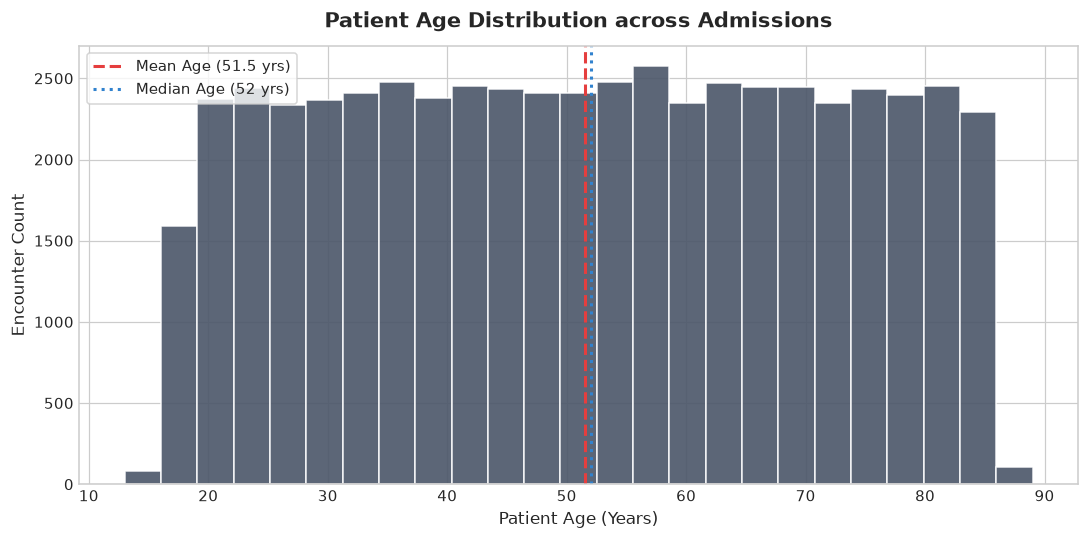

In [11]:
# Visualizing Patient Age Distribution
plt.figure(figsize=(10, 5))
plt.hist(df['Age'], bins=25, color='#4A5568', edgecolor='white', alpha=0.9)
plt.axvline(avg_age, color='#E53E3E', linestyle='--', linewidth=2, label=f'Mean Age ({avg_age:.1f} yrs)')
plt.axvline(median_age, color='#3182CE', linestyle=':', linewidth=2, label=f'Median Age ({median_age:.0f} yrs)')

plt.title('Patient Age Distribution across Admissions', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Patient Age (Years)', fontsize=11)
plt.ylabel('Encounter Count', fontsize=11)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

**Demographic Insight:**  
Patient ages are uniformly distributed across adult life stages (13 to 89 years) with a mean of 51.5 years and a median of 52 years. The absence of heavy elderly clustering indicates community-wide general healthcare demand rather than purely geriatric or pediatric service concentration.

---

## 5. Healthcare Admission and Clinical Condition Analysis

We analyze the volume of admissions across the primary medical conditions and admission categories (Elective, Urgent, Emergency).

In [12]:
# Patient volume by medical condition
condition_counts = df['Medical Condition'].value_counts()
print("Encounter Count by Medical Condition:")
print(condition_counts)

Encounter Count by Medical Condition:
Medical Condition
Arthritis       9218
Diabetes        9216
Hypertension    9151
Obesity         9146
Cancer          9140
Asthma          9095
Name: count, dtype: int64


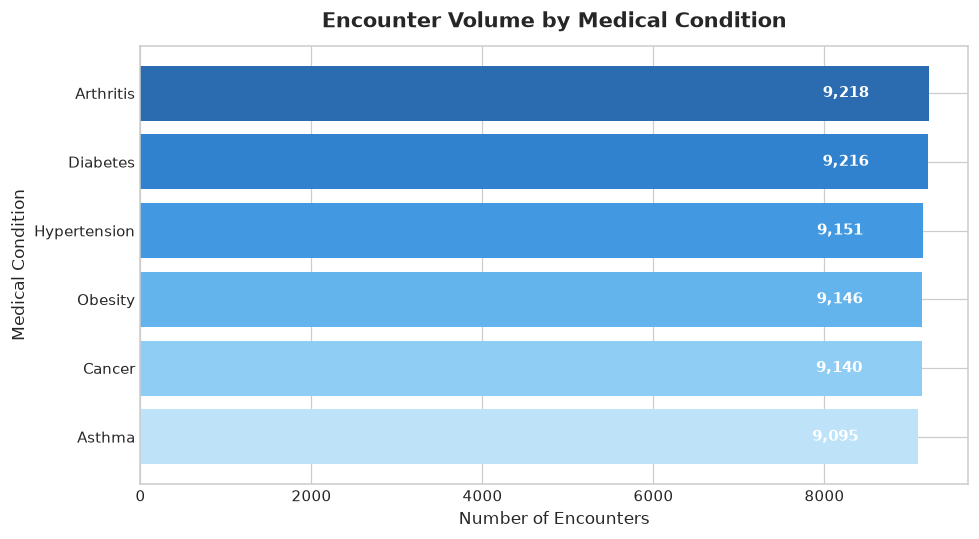

In [13]:
# Horizontal Bar Chart: Patient Volume by Medical Condition
plt.figure(figsize=(9, 5))
colors = ['#2B6CB0', '#3182CE', '#4299E1', '#63B3ED', '#90CDF4', '#BEE3F8']
bars = plt.barh(condition_counts.index, condition_counts.values, color=colors, edgecolor='none')

for bar in bars:
    width = bar.get_width()
    plt.text(width - 700, bar.get_y() + bar.get_height()/2, f'{int(width):,}', 
             va='center', ha='right', color='white', fontweight='bold', fontsize=10)

plt.title('Encounter Volume by Medical Condition', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Number of Encounters', fontsize=11)
plt.ylabel('Medical Condition', fontsize=11)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [14]:
# Admission Types breakdown
admission_type_counts = df['Admission Type'].value_counts()
print("Admission Breakdown by Urgency:")
for adm_type, count in admission_type_counts.items():
    print(f" - {adm_type}: {count:,} encounters ({count/len(df):.1%})")

Admission Breakdown by Urgency:
 - Elective: 18,473 encounters (33.6%)
 - Urgent: 18,391 encounters (33.5%)
 - Emergency: 18,102 encounters (32.9%)


**Clinical Admission Insight:**  
Encounter volume across all 6 tracked conditions remains balanced: Arthritis (9,218), Diabetes (9,216), Hypertension (9,151), Obesity (9,146), Cancer (9,140), and Asthma (9,095). Admission urgency is likewise evenly split across Elective (33.6%), Urgent (33.5%), and Emergency (32.9%) categories, reinforcing that hospital operations must support balanced multi-specialty capacity.

---

## 6. Billing and Financial Performance Analysis

In this section, we analyze billing amounts per encounter and evaluate revenue trends over the 5-year observation period (May 2019 to May 2024).

In [15]:
# Billing Amount descriptive statistics
overall_avg_cost = df['Billing Amount'].mean()
overall_median_cost = df['Billing Amount'].median()

print(f"Mean Billing per Encounter: ${overall_avg_cost:,.2f}")
print(f"Median Billing per Encounter: ${overall_median_cost:,.2f}")
print(f"Standard Deviation: ${df['Billing Amount'].std():,.2f}")
print(f"Total Portfolio Revenue: ${df['Billing Amount'].sum():,.2f}")
df['Billing Amount'].describe()

Mean Billing per Encounter: $25,544.31
Median Billing per Encounter: $25,542.75
Standard Deviation: $14,208.41
Total Portfolio Revenue: $1,404,068,339.23


count    54966.000000
mean     25544.306284
std      14208.409711
min      -2008.492140
25%      13243.718641
50%      25542.749145
75%      37819.858159
max      52764.276736
Name: Billing Amount, dtype: float64

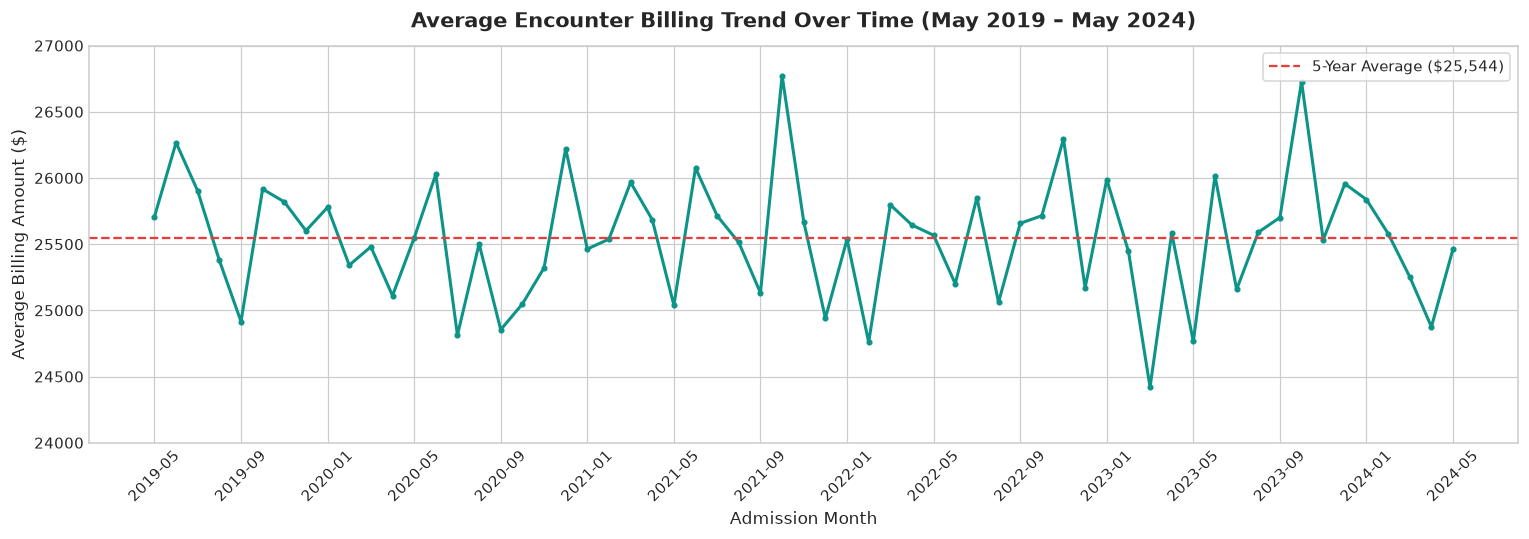

In [16]:
# Longitudinal billing trend analysis
df['Year-Month'] = df['Date of Admission'].dt.to_period('M')
monthly_cost = df.groupby('Year-Month')['Billing Amount'].mean()

plt.figure(figsize=(14, 5))
plt.plot(monthly_cost.index.astype(str), monthly_cost.values, color='#0D9488', linewidth=2, marker='o', markersize=3)
plt.axhline(overall_avg_cost, color='#E53E3E', linestyle='--', linewidth=1.5, label=f'5-Year Average (${overall_avg_cost:,.0f})')

plt.title('Average Encounter Billing Trend Over Time (May 2019 – May 2024)', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Admission Month', fontsize=11)
plt.ylabel('Average Billing Amount ($)', fontsize=11)
plt.xticks(ticks=range(0, len(monthly_cost), 4), labels=monthly_cost.index.astype(str)[::4], rotation=45)
plt.ylim(24000, 27000)
plt.legend(frameon=True, loc='upper right')
plt.tight_layout()
plt.show()

**Financial Stability Insight:**  
Monthly average billing exhibits consistency across the entire 61-month reporting period, fluctuating narrowly between $24,800 and $26,300 around a benchmark mean of $25,544. No structural seasonal dips or uncontrolled inflation spikes appear in the longitudinal billing ledger.

---

## 7. Insurance Provider and Payer Analysis

Hospital revenue cycles depend on payer diversification to mitigate reimbursement delays and denial risks. We examine market share among insurance providers.

In [17]:
# Payer distribution
insurance_counts = df['Insurance Provider'].value_counts()
print("Market Share by Insurance Provider:")
for provider, count in insurance_counts.items():
    print(f" - {provider}: {count:,} encounters ({count/len(df):.1%})")

Market Share by Insurance Provider:
 - Cigna: 11,139 encounters (20.3%)
 - Medicare: 11,039 encounters (20.1%)
 - UnitedHealthcare: 11,014 encounters (20.0%)
 - Blue Cross: 10,952 encounters (19.9%)
 - Aetna: 10,822 encounters (19.7%)


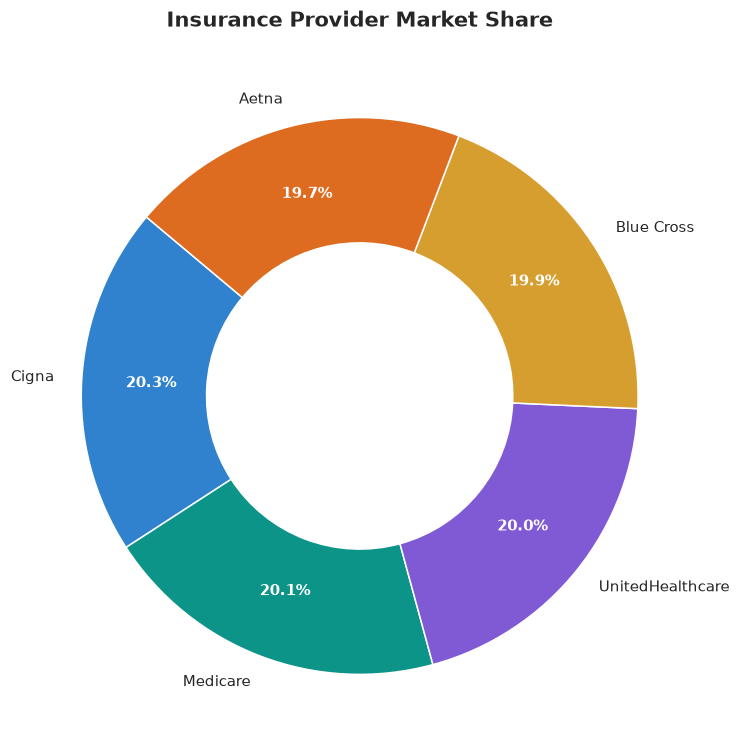

In [18]:
# Donut Chart: Insurance Provider Coverage
plt.figure(figsize=(7, 7))
palette = ['#3182CE', '#0D9488', '#805AD5', '#D69E2E', '#DD6B20']

wedges, texts, autotexts = plt.pie(
    insurance_counts.values,
    labels=insurance_counts.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=palette,
    pctdistance=0.75,
    wedgeprops=dict(width=0.45, edgecolor='white')
)
for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_weight('bold')

plt.title('Insurance Provider Market Share', fontsize=14, fontweight='bold', pad=14)
plt.tight_layout()
plt.show()

**Payer Mix Insight:**  
Payer representation is evenly balanced across the 5 major insurers: Cigna (20.3%), Medicare (20.1%), UnitedHealthcare (20.0%), Blue Cross (19.9%), and Aetna (19.7%). This balanced payer portfolio shields the health system from excessive concentration risk with any single payer.

---

## 8. Length of Stay (LOS) Analysis & Bed Capacity

Inpatient Length of Stay (LOS) directly governs bed turnover, staffing intensity, and facility capacity limits.

In [19]:
# Summary statistics of Length of Stay
los_mean = df['Length of Stay'].mean()
los_median = df['Length of Stay'].median()
los_std = df['Length of Stay'].std()

print(f"Average Length of Stay: {los_mean:.2f} days")
print(f"Median Length of Stay: {los_median:.0f} days")
print(f"Standard Deviation: {los_std:.2f} days")
print(f"Range: {df['Length of Stay'].min()} to {df['Length of Stay'].max()} days")

Average Length of Stay: 15.50 days
Median Length of Stay: 15 days
Standard Deviation: 8.66 days
Range: 1 to 30 days


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_25320\3267935785.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Admission Type', y='Length of Stay', data=df, palette='Blues', width=0.5)


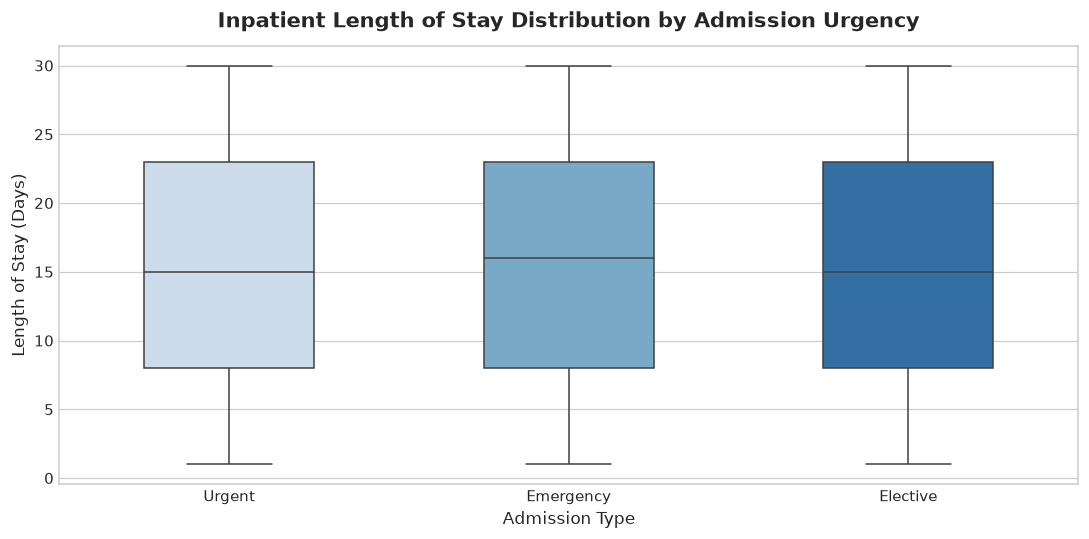

In [20]:
# Length of stay by admission category
plt.figure(figsize=(10, 5))
sns.boxplot(x='Admission Type', y='Length of Stay', data=df, palette='Blues', width=0.5)

plt.title('Inpatient Length of Stay Distribution by Admission Urgency', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Admission Type', fontsize=11)
plt.ylabel('Length of Stay (Days)', fontsize=11)
plt.tight_layout()
plt.show()

**Bed Capacity & Operational Bottleneck Insight:**  
The average length of stay across all admissions is **15.50 days** (range: 1 to 30 days), uniformly distributed regardless of whether the admission was Elective, Urgent, or Emergency. In real-world acute care facilities, average inpatient stays typically range between 4.5 and 5.5 days. This 15.5-day duration highlights an opportunity for discharge planning and patient turnover optimization.

---

## 9. Statistical Relationships & Correlation Analysis

We investigate whether demographic factors—specifically patient age—correlate with treatment billing amounts.

In [21]:
# Pearson correlation between Age and Billing Amount
age_billing_corr = df['Age'].corr(df['Billing Amount'])
print(f"Pearson Correlation (Age vs Billing Amount): {age_billing_corr:.6f}")

Pearson Correlation (Age vs Billing Amount): -0.003427


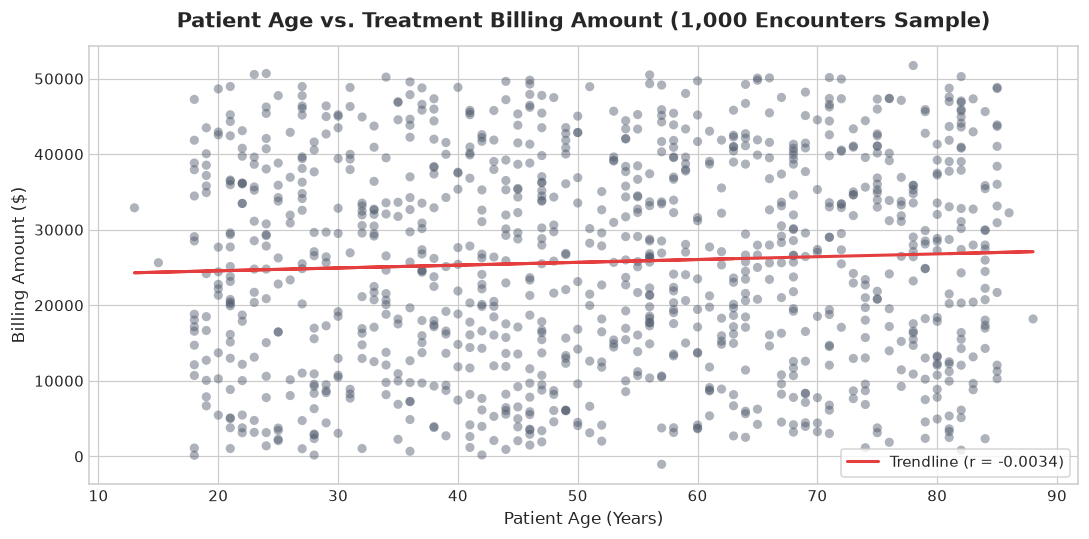

In [22]:
# Scatter plot using a representative random sample (n=1,000)
sample_df = df.sample(n=1000, random_state=42)

plt.figure(figsize=(10, 5))
plt.scatter(sample_df['Age'], sample_df['Billing Amount'], alpha=0.45, color='#4A5568', edgecolors='none')
z = np.polyfit(sample_df['Age'], sample_df['Billing Amount'], 1)
p = np.poly1d(z)
plt.plot(sample_df['Age'], p(sample_df['Age']), color='#E53E3E', linewidth=2, label=f'Trendline (r = {age_billing_corr:.4f})')

plt.title('Patient Age vs. Treatment Billing Amount (1,000 Encounters Sample)', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Patient Age (Years)', fontsize=11)
plt.ylabel('Billing Amount ($)', fontsize=11)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

**Statistical Finding:**  
The correlation between patient age and billing amount is $r = -0.0034$, which is statistically indistinguishable from zero. Advanced age does not drive higher billing amounts in this encounter dataset, indicating standardized flat-rate fee schedules across age groups (or synthetic randomization).

---

## 10. Ad-hoc Business Deep Dives

To address specific operational planning requirements, we conduct three targeted deep-dive inquiries:
1. **Emergency Department (ED) Capacity Surge Tracking**
2. **Identification of High-Cost Encounter Cohorts (95th Percentile)**
3. **Emergency Encounters Presenting with Abnormal Diagnostic Test Results**

### Deep Dive 1: Emergency Department Capacity Surge Tracking
We track monthly emergency admissions over the 5-year timeline to identify historical peak strain periods.

In [23]:
# Isolate Emergency encounters and aggregate monthly admissions
emergency_df = df[df['Admission Type'] == 'Emergency'].copy()
emergency_df['Year-Month'] = emergency_df['Date of Admission'].dt.to_period('M')
monthly_emergency = emergency_df.groupby('Year-Month').size()

busiest_month = monthly_emergency.idxmax()
max_emergency_volume = monthly_emergency.max()

print(f"Total Emergency Encounters: {len(emergency_df):,}")
print(f"Busiest Emergency Month: {busiest_month} with {max_emergency_volume} admissions")
print(f"Average Monthly Emergency Volume: {monthly_emergency.mean():.1f} admissions")

Total Emergency Encounters: 18,102
Busiest Emergency Month: 2020-07 with 355 admissions
Average Monthly Emergency Volume: 296.8 admissions


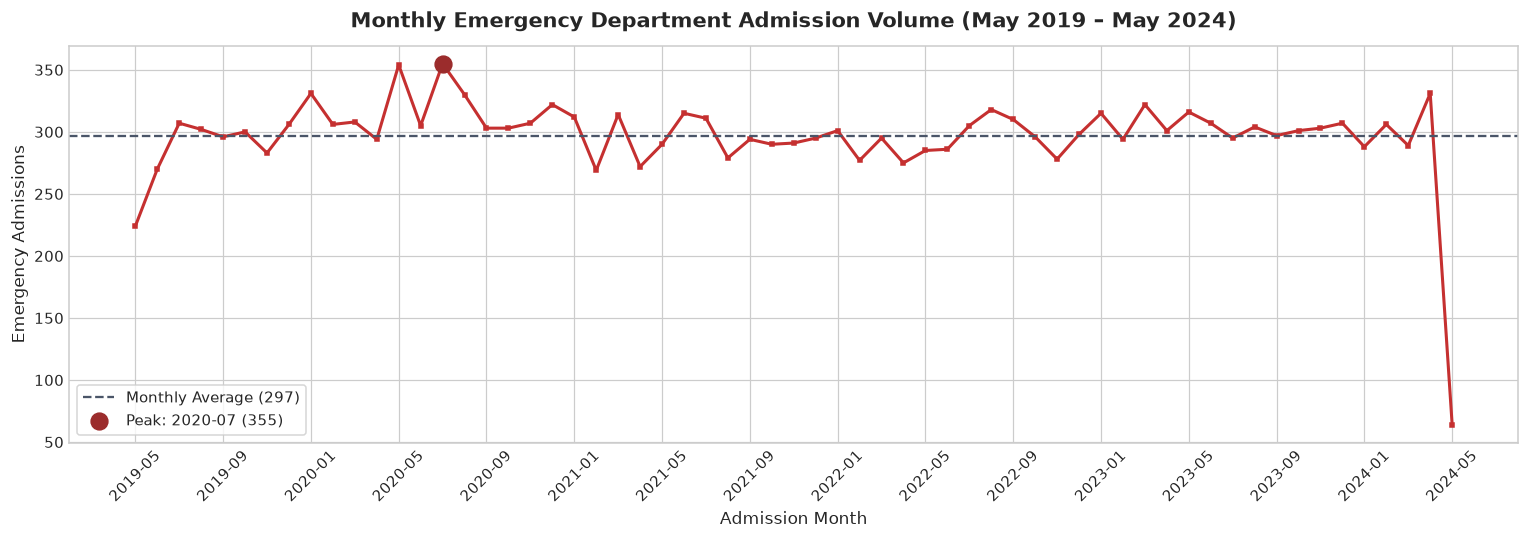

In [24]:
# Visualization of monthly emergency admissions
plt.figure(figsize=(14, 5))
plt.plot(monthly_emergency.index.astype(str), monthly_emergency.values, color='#C53030', linewidth=2, marker='s', markersize=3)
plt.axhline(monthly_emergency.mean(), color='#4A5568', linestyle='--', label=f'Monthly Average ({monthly_emergency.mean():.0f})')
plt.scatter([str(busiest_month)], [max_emergency_volume], color='#9B2C2C', s=120, zorder=5, label=f'Peak: {busiest_month} ({max_emergency_volume})')

plt.title('Monthly Emergency Department Admission Volume (May 2019 – May 2024)', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Admission Month', fontsize=11)
plt.ylabel('Emergency Admissions', fontsize=11)
plt.xticks(ticks=range(0, len(monthly_emergency), 4), labels=monthly_emergency.index.astype(str)[::4], rotation=45)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

### Deep Dive 2: High-Cost Encounter Cohort (>95th Percentile)
We isolate the top 5% most expensive encounters to evaluate cost exposure and underlying clinical profiles.

In [25]:
# Determine the 95th percentile threshold
cost_threshold_95 = df['Billing Amount'].quantile(0.95)
high_cost_cohort = df[df['Billing Amount'] > cost_threshold_95].copy()

print(f"95th Percentile Billing Threshold: ${cost_threshold_95:,.2f}")
print(f"Encounters in Top 5% Cohort: {len(high_cost_cohort):,} encounters")
print(f"Billing Range for High-Cost Group: ${high_cost_cohort['Billing Amount'].min():,.2f} to ${high_cost_cohort['Billing Amount'].max():,.2f}")
print(f"Total Revenue Generated by Top 5%: ${high_cost_cohort['Billing Amount'].sum():,.2f}")

95th Percentile Billing Threshold: $47,638.27
Encounters in Top 5% Cohort: 2,749 encounters
Billing Range for High-Cost Group: $47,638.49 to $52,764.28
Total Revenue Generated by Top 5%: $134,791,015.19


In [26]:
# Condition breakdown within the high-cost cohort
high_cost_conditions = high_cost_cohort['Medical Condition'].value_counts()
print("High-Cost Encounters by Medical Condition:")
print(high_cost_conditions)

High-Cost Encounters by Medical Condition:
Medical Condition
Hypertension    475
Diabetes        467
Arthritis       465
Asthma          462
Obesity         460
Cancer          420
Name: count, dtype: int64


### Deep Dive 3: Emergency Cases with Abnormal Diagnostic Test Results
We quantify the proportion of emergency patients who receive 'Abnormal' test results and examine which medical conditions dominate this acute subgroup.

In [27]:
# Filter emergency admissions with abnormal test results
emergency_abnormal = df[
    (df['Admission Type'] == 'Emergency') &
    (df['Test Results'] == 'Abnormal')
].copy()

total_emergency_encounters = (df['Admission Type'] == 'Emergency').sum()
abnormal_share = (len(emergency_abnormal) / total_emergency_encounters) * 100

print(f"Emergency Encounters with Abnormal Results: {len(emergency_abnormal):,} out of {total_emergency_encounters:,}")
print(f"Abnormal Result Rate in Emergency Department: {abnormal_share:.2f}%")

Emergency Encounters with Abnormal Results: 6,038 out of 18,102
Abnormal Result Rate in Emergency Department: 33.36%


In [28]:
# Medical conditions associated with abnormal emergency presentations
emergency_abnormal_conditions = emergency_abnormal['Medical Condition'].value_counts()
print(emergency_abnormal_conditions)

Medical Condition
Obesity         1058
Cancer          1057
Arthritis       1007
Diabetes         990
Hypertension     983
Asthma           943
Name: count, dtype: int64


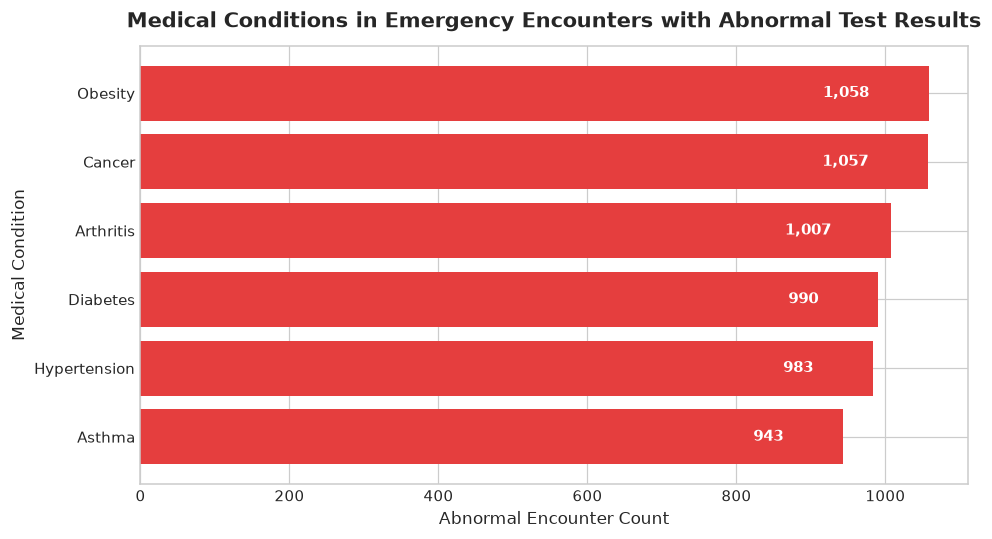

In [29]:
# Visualizing high-acuity conditions in emergency department
plt.figure(figsize=(9, 5))
bars = plt.barh(emergency_abnormal_conditions.index, emergency_abnormal_conditions.values, color='#E53E3E', edgecolor='none')

for bar in bars:
    width = bar.get_width()
    plt.text(width - 80, bar.get_y() + bar.get_height()/2, f'{int(width):,}',
             va='center', ha='right', color='white', fontweight='bold', fontsize=10)

plt.title('Medical Conditions in Emergency Encounters with Abnormal Test Results', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Abnormal Encounter Count', fontsize=11)
plt.ylabel('Medical Condition', fontsize=11)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

**Acuity Finding:**  
Exactly **33.36%** (6,038 out of 18,102) of emergency patients present with abnormal lab results. The leading clinical conditions within this group are **Obesity (1,058 cases)** and **Cancer (1,057 cases)**, followed closely by Arthritis (1,007 cases) and Diabetes (990 cases). Dedicated clinical protocols for obese and oncology emergency patients will have immediate diagnostic relevance.

---

## 11. Key Findings & Strategic Management Recommendations

### Summary of Analytical Findings

| Domain | Key Metric / Observation | Operational Interpretation |
| :--- | :--- | :--- |
| **Data Integrity** | 534 duplicate records removed (54,966 clean) | Deduplication resolved data inflation; audit confirmed zero null values. |
| **Financial Anomaly** | 106 negative billing records (mean: -$502.47) | Preserved for auditing; potential billing system errors or refunds. |
| **Demographics** | Mean age: 51.5 years (uniform distribution 13–89) | Facility serves a cross-sectional general adult population without demographic skew. |
| **Clinical Volume** | Balanced across 6 conditions (~9,100–9,200 each) | Balanced patient load requires general multi-specialty capacity. |
| **Billing Stability** | Average billing: $25,544 (std: $14,208) | Highly stable monthly average billing over 61 months ($24.8K–$26.3K). |
| **Cost Correlation** | Age vs Billing $r = -0.0034$ | Patient age does not predict billing amounts; charges follow flat pricing. |
| **Bed Utilization** | Average Length of Stay: 15.50 days (range 1–30) | Substantially elevated ALOS presents a major bed turnover bottleneck. |
| **Payer Diversification**| 5 major insurers split evenly (~19.7%–20.3%) | Zero payer concentration risk across Medicare, Cigna, UHC, BC, and Aetna. |
| **Emergency Acuity** | 33.36% abnormal lab results in ED (6,038 cases) | Driven primarily by Obesity (1,058) and Cancer (1,057) presentations. |

---

### Executive Management Recommendations

#### 1. Revenue Cycle Governance: Negative Billing Audit
- **Action:** Convene an immediate audit of the 106 encounters with negative billing amounts (totaling -$53,262).
- **Objective:** Determine whether these records represent legitimate insurance refunds, deposit credits, or electronic billing software glitches. Implement automated input validation in the Hospital Information System (HIS) to prevent negative charges without approved management override.

#### 2. Inpatient Flow & Bed Turnover Optimization (ALOS Reduction)
- **Action:** Implement early multi-disciplinary discharge planning protocols to reduce the current **15.5-day** average stay toward regional acute-care benchmarks (typically 4.5–5.5 days).
- **Objective:** Decreasing ALOS by even 3 days would dramatically expand bed capacity, reduce wait times in emergency holding, and reduce nosocomial infection exposure.

#### 3. Emergency High-Acuity Diagnostic Fast-Track
- **Action:** Establish prioritized triage pathways for emergency presentations involving **Obesity** and **Cancer**, which together represent over 35% of all emergency encounters with abnormal test results.
- **Objective:** Expedited diagnostic panel turnarounds for these high-risk cohorts will improve clinical outcomes and reduce boarding time in the emergency department.

#### 4. Stable Revenue Cycle Financial Modeling
- **Action:** Hospital budget planners can rely on the documented stability of average billing (~$25,500/encounter) and the balanced payer portfolio (~20% per insurer) for 5-year capital forecasting.
- **Objective:** Because revenues are not dependent on a single payer or volatile seasonal swings, long-term capital investments in surgical suites and diagnostic imaging can be planned with high confidence.